# Chapter 72: Redistribution, Social Insurance, Giving, and Patronage

This notebook reruns four worked examples from the chapter: the median voter's return from a linear tax and equal transfer, the Samaritan's dilemma in disaster relief, a benefit phaseout, and a tax-financed transfer judged with welfare weights. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def meltzer_richard(z, t, slope=0.1, median_index=None):
    """Linear tax t with an equal transfer b = t mean(y), where y_i(t) = (1 - slope t) z_i.

    Principle: meltzer-richard-redistribution-mechanism. Book (ch072): z = 18, 28, 38, 58, 108,
    t = 0.20: mean 50, factor 0.98, taxable mean 49, b 9.80, y_m 37.24, c_m 39.592; with top 158:
    mean 60, taxable mean 58.80, b 11.76, c_m 41.552.
    """
    zs = sorted(float(v) for v in z)
    n = len(zs)
    zm = zs[n // 2] if median_index is None else zs[median_index]
    mean = sum(zs) / n
    factor = 1 - slope * t
    taxable_mean = factor * mean
    b = t * taxable_mean
    ym = factor * zm
    cm = (1 - t) * ym + b
    return {"mean": mean, "median": zm, "factor": factor, "taxable_mean": taxable_mean, "transfer": b,
            "ym": ym, "cm": cm, "gain": cm - zm, "after_tax_ym": (1 - t) * ym}


def samaritan_costs(prep, loss_n, loss_p, coverage):
    """Household private costs with relief covering a share of any loss.

    J_N = (1 - c) loss_n, J_P = prep + (1 - c) loss_p; the household prepares when J_P < J_N
    (a tie is reported). Principle: samaritans-dilemma. Book (ch072): prep 24, losses 120 and 50:
    c = 0.75 gives 30 and 36.50 (no preparation); c = 0.50 gives 60 and 49 (prepares);
    resources 120 vs 24 + 50 = 74, saving 46.
    """
    jn = (1 - coverage) * loss_n
    jp = prep + (1 - coverage) * loss_p
    res_n, res_p = loss_n, prep + loss_p
    return {"J_N": jn, "J_P": jp, "prepares": jp < jn, "tie": abs(jp - jn) < 1e-9, "resources_N": res_n,
            "resources_P": res_p, "saving": res_n - res_p, "efficient_prepare": res_p < res_n}


def phaseout_transfer(earn, guarantee, rate):
    """Benefit T(e) = max(0, B - p e) and disposable income e + T(e).

    Principle: welfare-redistribution. Book (ch072): B = 9,000, p = 0.40: T(12,000) = 4,200,
    T(18,000) = 1,800, disposable 16,200 and 19,800; p = 0.20: 6,600, 5,400, 18,600, 23,400.
    """
    benefit = max(0.0, guarantee - rate * earn)
    return {"benefit": benefit, "disposable": earn + benefit, "phased_out": benefit == 0.0}


def linear_tax_wedge(a, b, c, d, t):
    """Per-unit tax t in a market with inverse demand P = a - bQ and inverse supply P = c + dQ.

    Principle: deadweight-loss. Book (ch006): a=20, b=0.10, c=4, d=0.10 (Q in hundreds of visits),
    t=4 gives Q0 = 80, Q_t = 60, buyer price 14, seller price 10, revenue 240, CS 180, PS 180,
    DWL 40 (hundreds of dollars: 24,000, 18,000, 18,000, 4,000).
    """
    q0 = (a - c) / (b + d)
    q = max((a - c - t) / (b + d), 0.0)
    pd, ps = a - b * q, c + d * q
    return {"q0": q0, "p0": a - b * q0, "q": q, "pd": pd, "ps": ps, "revenue": t * q,
            "cs": 0.5 * (a - pd) * q, "ps_surplus": 0.5 * (ps - c) * q, "dwl": deadweight_loss(t, q0 - q),
            "total0": 0.5 * (a - c) * q0}


def deadweight_loss(t, dQ):
    """Harberger triangle 0.5 t dQ. Principle: deadweight-loss. Book (ch006): 0.5(4)(2,000) = 4,000."""
    return 0.5 * t * dQ


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(meltzer_richard=meltzer_richard, samaritan_costs=samaritan_costs, phaseout_transfer=phaseout_transfer)


equilibrium = SimpleNamespace(linear_tax_wedge=linear_tax_wedge, deadweight_loss=deadweight_loss)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'meltzer-richard-redistribution-mechanism': {'z': [18, 28, 38, 58, 108],
                                              'mean': 50,
                                              'median': 38,
                                              'slope': 0.1,
                                              't': 0.2,
                                              'factor': 0.98,
                                              'taxable_mean': 49,
                                              'b': 9.8,
                                              'ym': 37.24,
                                              'cm': 39.592,
                                              'top_2': 158,
                                              'mean_2': 60,
                                              'taxable_mean_2': 58.8,
                                              'b_2': 11.76,
                                              'after_tax_ym': 29.792,
                                              'cm_2': 41.552},
 'samaritans-dilemma': {'prep': 24,
                        'loss_n': 120,
                        'loss_p': 50,
                        'coverage': 0.75,
                        'J_N': 30,
                        'J_P': 36.5,
                        'resources_P': 74,
                        'saving': 46,
                        'coverage_2': 0.5,
                        'J_N_2': 60,
                        'J_P_2': 49},
 'welfare-redistribution': {'B': 9000,
                            'p': 0.4,
                            'e1': 12000,
                            'e2': 18000,
                            'T1': 4200,
                            'T2': 1800,
                            'y1': 16200,
                            'y2': 19800,
                            'gain': 3600,
                            'p_2': 0.2,
                            'T1_2': 6600,
                            'T2_2': 5400,
                            'y1_2': 18600,
                            'y2_2': 23400,
                            'gain_2': 4800,
                            'extra_1': 2400,
                            'extra_2': 3600},
 'welfare-economics-redistribution': {'a': 120,
                                      'c': 20,
                                      't': 18,
                                      'p0': 70,
                                      'q0': 50,
                                      'ps': 61,
                                      'pb': 79,
                                      'q': 41,
                                      'R': 738,
                                      'D': 81,
                                      'admin': 30,
                                      'w': 1.4,
                                      'dW': 184.2,
                                      'dW_equal': -111},
 'constructed': {'meltzer-richard-redistribution-mechanism': {'top': [133, 208], 't': [0.1, 0.3]},
                 'samaritans-dilemma': {'coverage': [0.25, 1.0], 'prep': [16, 32]},
                 'welfare-redistribution': {'p': [0.3, 0.5], 'B': [6000, 12000]},
                 'welfare-economics-redistribution': {'t': [6, 12, 24], 'w': [1.2]}}}


def fx(x):
    """Exact short decimal: at least 2 and at most 4 decimals, trailing zeros beyond 2 removed."""
    text = num(x, 4)
    while text.endswith("0") and len(text.split(".")[1]) > 2:
        text = text[:-1]
    return text


def pc(fraction):
    """Percent without trailing zeros: 0.2 -> '20', 0.25 -> '25'."""
    return fx(100 * fraction).rstrip("0").rstrip(".")


def median_voter_picture(top=108, t=0.20):
    bv = BV["meltzer-richard-redistribution-mechanism"]
    z = bv["z"][:4] + [top]
    r = public.meltzer_richard(z, t, bv["slope"])
    fig, (ax, ax2) = new_figure(2)
    xs = np.arange(5)
    cols = [PALETTE["light"]] * 5
    cols[2] = PALETTE["teal"]
    ax.bar(xs, z, color=cols, width=0.6)
    for x, v in zip(xs, z):
        ax.annotate(num(v, 0), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                    fontsize=10.5, color=PALETTE["ink"], zorder=6,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(r["mean"], color=PALETTE["gold"], linestyle="dashed", linewidth=1.4, label=f"mean {num(r['mean'], 0)}")
    ax.axhline(r["median"], color=PALETTE["teal"], linestyle="dotted", linewidth=1.6,
               label=f"median {num(r['median'], 0)}")
    ax.legend(loc="upper left", frameon=False)
    ax.set_xticks(xs, ["1", "2", "3", "4", "5"])
    ax.set_ylim(0, 235)
    ax.set_xlabel("Voter (median voter in teal)")
    ax.set_ylabel("Baseline earnings z")
    names = ["Baseline z_m", "Kept (1 - t) y_m", "Transfer b", "c_m"]
    vals = [r["median"], r["after_tax_ym"], r["transfer"], r["cm"]]
    bar_cols = [PALETTE["grey"], PALETTE["navy"], PALETTE["gold"], PALETTE["teal"]]
    ax2.bar(range(4), vals, color=bar_cols, width=0.6)
    for x, v in enumerate(vals):
        ax2.annotate(num(v, 0) if x == 0 else fx(v), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                     fontsize=10.5, color=PALETTE["ink"])
    ax2.axhline(r["median"], color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    ax2.set_xticks(range(4), ["baseline", "kept", "transfer", "total"])
    ax2.set_ylim(0, 58)
    ax2.set_xlabel(f"Median voter at t = {num(t)}")
    ax2.set_ylabel("Resources")
    gain = r["cm"] - r["median"]
    side = "above" if gain > 0 else ("equal to" if abs(gain) < 1e-9 else "below")
    metrics = {"Mean earnings": num(r["mean"], 0), "Response factor 1 - 0.1t": num(r["factor"]),
               "Mean taxable earnings": fx(r["taxable_mean"]), "Transfer b": fx(r["transfer"]),
               "Median taxable earnings y_m": fx(r["ym"]), "Median disposable resources c_m": fx(r["cm"]),
               "Change from baseline 38": fx(gain)}
    steps = [f"Mean = (18 + 28 + 38 + 58 + {top}) / 5 = {num(r['mean'], 0)}",
             f"Response factor = 1 - 0.1 x {num(t)} = {num(r['factor'])}",
             f"Mean taxable earnings = {num(r['factor'])} x {num(r['mean'], 0)} = {fx(r['taxable_mean'])}",
             f"b = {num(t)} x {fx(r['taxable_mean'])} = {fx(r['transfer'])}",
             f"y_m = {num(r['factor'])} x 38 = {fx(r['ym'])}",
             f"c_m = {num(1 - t)} x {fx(r['ym'])} + {fx(r['transfer'])} = {fx(r['after_tax_ym'])} + "
             f"{fx(r['transfer'])} = {fx(r['cm'])}"]
    interp = (f"The top earner's {top} pulls the mean to {num(r['mean'], 0)}, while the median stays at 38. At "
              f"t = {num(t)} taxable earnings shrink by the factor {num(r['factor'])}, so the equal transfer is "
              f"{num(t)} x {fx(r['taxable_mean'])} = {fx(r['transfer'])}. The median voter keeps {num(1 - t)} x "
              f"{fx(r['ym'])} = {fx(r['after_tax_ym'])} and ends with c_m = {fx(r['cm'])}, {side} the baseline 38. "
              f"This is a mechanical comparison: it leaves the value of extra leisure uncounted and does not show "
              f"that this rate is the voter's best one.")
    alt = (f"Left: baseline earnings 18, 28, 38, 58 and {top}, with the mean {num(r['mean'], 0)} above the median 38. "
           f"Right: the median voter's baseline 38, kept earnings {fx(r['after_tax_ym'])}, transfer "
           f"{fx(r['transfer'])} and disposable resources {fx(r['cm'])} at t = {num(t)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def samaritan_picture(c=0.75, k=24):
    bv = BV["samaritans-dilemma"]
    ln, lp = bv["loss_n"], bv["loss_p"]
    r = public.samaritan_costs(k, ln, lp, c)
    fig, ax = new_figure()
    xs = np.array([0.0, 1.0])
    w = 0.34
    ax.bar(xs - w / 2, [r["resources_N"], r["resources_P"]], width=w, color=PALETTE["light"],
           label="total resource use")
    ax.bar(xs + w / 2, [r["J_N"], r["J_P"]], width=w, color=[PALETTE["terracotta"], PALETTE["teal"]],
           label="household's own cost")
    for x, v in zip(xs - w / 2, [r["resources_N"], r["resources_P"]]):
        ax.annotate(num(v, 0), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                    fontsize=10.5, color=PALETTE["ink"])
    for x, v in zip(xs + w / 2, [r["J_N"], r["J_P"]]):
        ax.annotate(num(v), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                    fontsize=10.5, color=PALETTE["ink"])
    ax.set_xticks(xs, ["No preparation", "Prepare"])
    ax.set_ylim(0, 150)
    ax.set_xlim(-0.6, 1.6)
    ax.legend(loc="upper right", frameon=False)
    ax.set_ylabel("Cost")
    ax.set_xlabel(f"Relief covers {pc(c)} percent of any loss; preparation costs {k}")
    u = 1 - c
    if r["tie"]:
        choice = "Indifferent (tie)"
        verdict = f"J_N and J_P are equal at {num(r['J_N'])}, so the household is indifferent."
    elif r["prepares"]:
        choice = "Prepares"
        verdict = f"Because {num(r['J_P'])} < {num(r['J_N'])}, the household prepares, which also saves resources."
    else:
        choice = "Does not prepare"
        verdict = (f"Because {num(r['J_N'])} < {num(r['J_P'])}, the household does not prepare, even though "
                   f"preparing would save {num(r['saving'], 0)} of total resources.")
    metrics = {"Own cost without preparation J_N": num(r["J_N"]), "Own cost with preparation J_P": num(r["J_P"]),
               "Household choice": choice, "Resource use without preparation": num(r["resources_N"], 0),
               "Resource use with preparation": num(r["resources_P"], 0),
               "Resource saving from preparing": num(r["saving"], 0)}
    steps = [f"J_N = (1 - {num(c)}) x 120 = {num(u)} x 120 = {num(r['J_N'])}",
             f"J_P = {k} + (1 - {num(c)}) x 50 = {k} + {num(u * lp)} = {num(r['J_P'])}",
             f"Resources: 120 without preparation, {k} + 50 = {num(r['resources_P'], 0)} with it",
             f"Resource saving = 120 - {num(r['resources_P'], 0)} = {num(r['saving'], 0)}"]
    interp = (f"With relief covering {pc(c)} percent, the household bears {num(u)} of each loss: J_N = "
              f"{num(u)} x 120 = {num(r['J_N'])} and J_P = {k} + {num(u)} x 50 = {num(r['J_P'])}. {verdict} The comparison shows a response margin; it "
              f"does not pick a real coverage rule, which also needs liquidity, inequality and catastrophic risk.")
    alt = (f"Paired bars. Without preparation the household pays {num(r['J_N'])} of a 120 resource loss; with "
           f"preparation it pays {num(r['J_P'])} of {num(r['resources_P'], 0)}. Choice: {choice.lower()}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def phaseout_picture(p=0.40, guarantee=9_000):
    B = guarantee
    bv = BV["welfare-redistribution"]
    e1, e2 = bv["e1"], bv["e2"]
    r1 = public.phaseout_transfer(e1, B, p)
    r2 = public.phaseout_transfer(e2, B, p)
    gain = r2["disposable"] - r1["disposable"]
    kept = gain / (e2 - e1)
    fig, ax = new_figure()
    es = np.linspace(0, 32_000, 400)
    ax.plot(es / 1000, [public.phaseout_transfer(e, B, p)["disposable"] / 1000 for e in es], color=PALETTE["teal"],
            linewidth=2.2, label="disposable income")
    ax.plot(es / 1000, es / 1000, color=PALETTE["grey"], linestyle="dashed", linewidth=1.3,
            label="earnings only (no benefit)")
    mark(ax, e1 / 1000, r1["disposable"] / 1000, f"{num(r1['disposable'], 0)}", col="navy", dx=-8, dy=8, ha="right")
    mark(ax, e2 / 1000, r2["disposable"] / 1000, f"{num(r2['disposable'], 0)}", col="navy", dx=8, dy=-10, va="top")
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlim(0, 32)
    ax.set_ylim(0, 36)
    ax.set_xlabel("Earnings (thousand)")
    ax.set_ylabel("Disposable income (thousand)")

    def tline(e, rr):
        raw = B - p * e
        if raw >= 0:
            return f"T({num(e, 0)}) = {num(B, 0)} - {num(p)} x {num(e, 0)} = {num(rr['benefit'], 0)}"
        return f"T({num(e, 0)}) = {num(B, 0)} - {num(p)} x {num(e, 0)} = {num(raw, 0)}, floored at 0"

    metrics = {"Benefit at 12,000": num(r1["benefit"], 0), "Benefit at 18,000": num(r2["benefit"], 0),
               "Disposable income at 12,000": num(r1["disposable"], 0),
               "Disposable income at 18,000": num(r2["disposable"], 0),
               "Gain from 6,000 more earnings": num(gain, 0), "Share of the 6,000 kept": f"{num(100 * kept, 0)}%"}
    steps = [tline(e1, r1), tline(e2, r2),
             f"Disposable incomes: 12,000 + {num(r1['benefit'], 0)} = {num(r1['disposable'], 0)} and 18,000 + "
             f"{num(r2['benefit'], 0)} = {num(r2['disposable'], 0)}",
             f"Gain = {num(r2['disposable'], 0)} - {num(r1['disposable'], 0)} = {num(gain, 0)}",
             f"Share kept = {num(gain, 0)} / 6,000 = {num(100 * kept, 0)}%"]
    end = B / p
    if end <= e1:
        note = (f"At this guarantee and rate the benefit has reached zero by 12,000 (it ends at "
                f"{num(end, 0)}), so the household keeps all of the extra 6,000.")
    elif end < e2:
        note = (f"The benefit ends at {num(B / p, 0)}, before 18,000, so the household keeps {num(100 * kept, 0)} "
                f"percent rather than the {num(100 * (1 - p), 0)} percent the rate alone implies.")
    else:
        edge = (f" The benefit reaches zero exactly at {num(end, 0)}, so the whole raise lies inside the phaseout "
                f"range." if abs(end - e2) < 1e-9 else "")
        note = (f"Each extra unit earned withdraws {num(p)} of benefit, so the household keeps "
                f"{num(100 * kept, 0)} percent of the extra 6,000.{edge}")
    interp = (f"With guarantee {num(B, 0)} and phaseout {num(p)}, the benefit is {num(r1['benefit'], 0)} at 12,000 "
              f"and {num(r2['benefit'], 0)} at 18,000, so disposable income rises from {num(r1['disposable'], 0)} to "
              f"{num(r2['disposable'], 0)}: {num(r2['disposable'], 0)} - {num(r1['disposable'], 0)} = {num(gain, 0)}. {note} A gentler phaseout raises payments, so "
              f"choosing a schedule needs a financing plan and a stated objective.")
    alt = (f"Disposable income against earnings for guarantee {num(B, 0)} and phaseout {num(p)}, with the "
           f"earnings-only line for comparison. Points mark {num(r1['disposable'], 0)} at earnings 12,000 and "
           f"{num(r2['disposable'], 0)} at 18,000.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def weights_picture(t=18, w=1.4):
    bv = BV["welfare-economics-redistribution"]
    admin = bv["admin"]
    m = equilibrium.linear_tax_wedge(120, 1, 20, 1, t)
    R, D, q = m["revenue"], m["dwl"], m["q"]
    dW = w * R - R - D - admin
    fig, (ax, ax2) = new_figure(2)
    qs = np.linspace(0, 100, 200)
    ax.plot(qs, 120 - qs, color=PALETTE["navy"], linewidth=2, label="demand")
    ax.plot(qs, 20 + qs, color=PALETTE["teal"], linewidth=2, label="supply")
    ax.fill_between([0, q], [m["ps"], m["ps"]], [m["pd"], m["pd"]], color=PALETTE["gold"], alpha=0.35)
    ax.fill([q, m["q0"], q], [m["pd"], m["p0"], m["ps"]], color=PALETTE["terracotta"], alpha=0.55)
    mark(ax, q, m["pd"], f"P_b = {num(m['pd'], 0)}", col="navy", dx=8, dy=6)
    mark(ax, q, m["ps"], f"P_s = {num(m['ps'], 0)}", col="teal", dx=8, dy=-8, va="top")
    label(ax, q / 2, (m["pd"] + m["ps"]) / 2, f"R = {num(R, 0)}", col="gold", dx=0, dy=0, ha="center", va="center")
    ax.text(0.97, 0.05, f"red triangle: deadweight loss D = {num(D, 0)}", transform=ax.transAxes, ha="right",
            va="bottom", fontsize=10.5, color=PALETTE["terracotta"])
    ax.legend(loc="lower left", frameon=False)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 125)
    ax.set_xlabel(f"Quantity (Q = {num(q, 0)} with the levy)")
    ax.set_ylabel("Price")
    names = ["recipients", "payers", "distortion", "admin", "net"]
    vals = [w * R, -R, -D, -admin, dW]
    cols = [PALETTE["teal"], PALETTE["navy"], PALETTE["terracotta"], PALETTE["grey"],
            PALETTE["gold"] if dW >= 0 else PALETTE["terracotta"]]
    ax2.bar(range(5), vals, color=cols, width=0.6)
    for x, v in enumerate(vals):
        ax2.annotate(num(v, 1), (x, v), xytext=(0, 3 if v >= 0 else -3), textcoords="offset points", ha="center",
                     va="bottom" if v >= 0 else "top", fontsize=10.5, color=PALETTE["ink"])
    ax2.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax2.set_xticks(range(5), names)
    ax2.set_ylim(-1250, 1650)
    ax2.set_ylabel("Weighted welfare change")
    ax2.set_xlabel(f"Recipient weight {num(w, 1)}, payer weight 1")
    sign = "raises" if dW > 0 else ("leaves unchanged" if abs(dW) < 1e-9 else "lowers")
    metrics = {"Seller price P_s": num(m["ps"], 0), "Buyer price P_b": num(m["pd"], 0), "Quantity Q": num(q, 0),
               "Revenue R": num(R, 0), "Deadweight loss D": num(D, 0), "Administration": num(admin, 0),
               "Welfare change Delta W": num(dW, 1)}
    steps = [f"120 - (P_s + {t}) = P_s - 20, so P_s = {num(m['ps'], 0)}, P_b = {num(m['pd'], 0)}, Q = {num(q, 0)}",
             f"R = {t} x {num(q, 0)} = {num(R, 0)}",
             f"D = 0.5 x {t} x {num(m['q0'] - q, 0)} = {num(D, 0)}",
             f"Delta W = {num(w, 1)} x {num(R, 0)} - {num(R, 0)} - {num(D, 0)} - {num(admin, 0)} = "
             f"{num(w * R, 1)} - {num(R + D + admin, 0)} = {num(dW, 1)}"]
    interp = (f"A levy of {t} splits evenly: buyers pay {num(m['pd'], 0)} and sellers get {num(m['ps'], 0)}, each "
              f"{num(t / 2, 0)} away from 70. It raises {num(R, 0)} at a distortion of {num(D, 0)}, and "
              f"administration uses {num(admin, 0)}. With recipient weight {num(w, 1)}, Delta W = "
              f"{num(w, 1)} x {num(R, 0)} - {num(R, 0)} - {num(D, 0)} - {num(admin, 0)} = {num(dW, 1)}, so "
              f"the transfer {sign} measured welfare. The {num(D, 0)} and {num(admin, 0)} are resource losses under "
              f"any weights; only the normative weight moves the ranking.")
    alt = (f"Left: demand 120 - Q and supply 20 + Q with a levy of {t}, buyer price {num(m['pd'], 0)}, seller price "
           f"{num(m['ps'], 0)} and quantity {num(q, 0)}; the revenue rectangle is {num(R, 0)} and the triangle "
           f"{num(D, 0)}. Right: weighted gains and losses summing to {num(dW, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Meltzer-Richard mechanism: the median voter and the mean-median gap

Five voters earn 18, 28, 38, 58 and 108, and taxable earnings respond as $y_i(t)=(1-0.1t)z_i$. Revenue is returned as an equal transfer.

$$\bar z=\frac{18+28+38+58+108}{5}=50, \qquad b(0.20)=0.20\times49=9.80$$

$$c_m(0.20)=0.80\times37.24+9.80=39.592$$

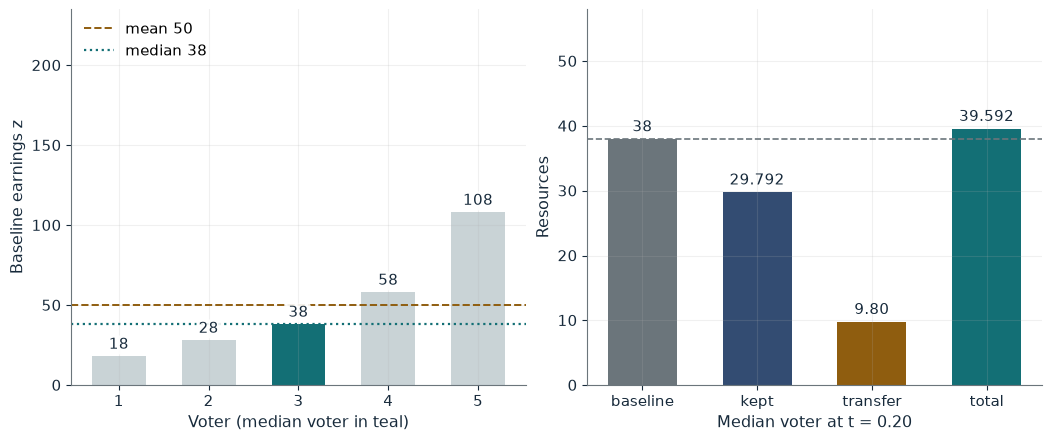

Mean earnings                    50
Response factor 1 - 0.1t         0.98
Mean taxable earnings            49.00
Transfer b                       9.80
Median taxable earnings y_m      37.24
Median disposable resources c_m  39.592
Change from baseline 38          1.592

Worked steps:
  1. Mean = (18 + 28 + 38 + 58 + 108) / 5 = 50
  2. Response factor = 1 - 0.1 x 0.20 = 0.98
  3. Mean taxable earnings = 0.98 x 50 = 49.00
  4. b = 0.20 x 49.00 = 9.80
  5. y_m = 0.98 x 38 = 37.24
  6. c_m = 0.80 x 37.24 + 9.80 = 29.792 + 9.80 = 39.592

The top earner's 108 pulls the mean to 50, while the median stays at 38. At t = 0.20 taxable earnings shrink by the factor 0.98, so the equal transfer is 0.20 x 49.00 = 9.80. The median voter keeps 0.80 x 37.24 = 29.792 and ends with c_m = 39.592, above the baseline 38. This is a mechanical comparison: it leaves the value of extra leisure uncounted and does not show that this rate is the voter's best one.


In [2]:
show(median_voter_picture(top=108, t=0.20))

Change one input, `top`, and hold the others at the book's values:

In [3]:
sweep(median_voter_picture, 'top', [108, 133, 158, 208], {'t': 0.2}, ['Mean earnings', 'Transfer b', 'Median disposable resources c_m'])

top | Mean earnings | Transfer b | Median disposable resources c_m
108 | 50 | 9.80 | 39.592
133 | 55 | 10.78 | 40.572
158 | 60 | 11.76 | 41.552
208 | 70 | 13.72 | 43.512


The median voter ends with 39.592, above the baseline 38. Raising only the top income to 158 lifts the transfer to 11.76 and c_m to 41.552: a wider mean-median gap raises her return at this rate, without showing that 0.20 is her best rate.

## 2. Samaritan's dilemma: relief coverage and preparation

Preparation costs 24 and cuts a possible loss from 120 to 50; relief covers a share of either loss.

$$J_N=(1-0.75)\times120=30, \qquad J_P=24+(1-0.75)\times50=36.50$$

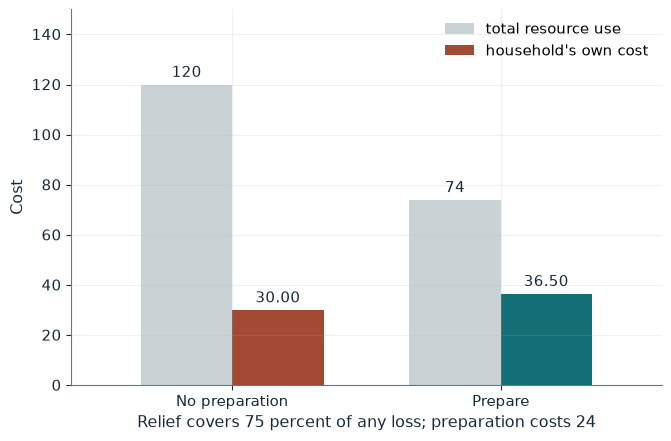

Own cost without preparation J_N  30.00
Own cost with preparation J_P     36.50
Household choice                  Does not prepare
Resource use without preparation  120
Resource use with preparation     74
Resource saving from preparing    46

Worked steps:
  1. J_N = (1 - 0.75) x 120 = 0.25 x 120 = 30.00
  2. J_P = 24 + (1 - 0.75) x 50 = 24 + 12.50 = 36.50
  3. Resources: 120 without preparation, 24 + 50 = 74 with it
  4. Resource saving = 120 - 74 = 46

With relief covering 75 percent, the household bears 0.25 of each loss: J_N = 0.25 x 120 = 30.00 and J_P = 24 + 0.25 x 50 = 36.50. Because 30.00 < 36.50, the household does not prepare, even though preparing would save 46 of total resources. The comparison shows a response margin; it does not pick a real coverage rule, which also needs liquidity, inequality and catastrophic risk.


In [4]:
show(samaritan_picture(c=0.75, k=24))

Change one input, `c`, and hold the others at the book's values:

In [5]:
sweep(samaritan_picture, 'c', [0.25, 0.5, 0.75, 1.0], {'k': 24}, ['Own cost without preparation J_N', 'Own cost with preparation J_P', 'Household choice'])

c | Own cost without preparation J_N | Own cost with preparation J_P | Household choice
0.25 | 90.00 | 61.50 | Prepares
0.5 | 60.00 | 49.00 | Prepares
0.75 | 30.00 | 36.50 | Does not prepare
1.0 | 0.00 | 24.00 | Does not prepare


At 75 percent coverage the household skips preparation although it would save 46 of resources. At 50 percent, J_N = 60 and J_P = 49, so it prepares.

## 3. Benefit phaseout: the reward to earning more

The benefit is $T(e)=B-pe$, never below zero, with guarantee $B=9{,}000$.

$$T(12{,}000)=9{,}000-0.40(12{,}000)=4{,}200, \qquad T(18{,}000)=9{,}000-0.40(18{,}000)=1{,}800$$

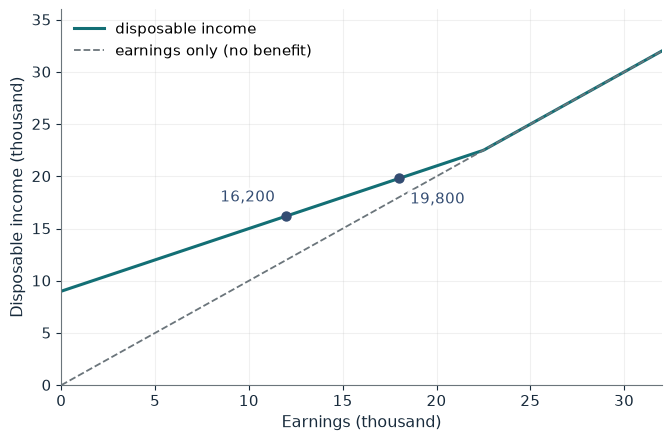

Benefit at 12,000              4,200
Benefit at 18,000              1,800
Disposable income at 12,000    16,200
Disposable income at 18,000    19,800
Gain from 6,000 more earnings  3,600
Share of the 6,000 kept        60%

Worked steps:
  1. T(12,000) = 9,000 - 0.40 x 12,000 = 4,200
  2. T(18,000) = 9,000 - 0.40 x 18,000 = 1,800
  3. Disposable incomes: 12,000 + 4,200 = 16,200 and 18,000 + 1,800 = 19,800
  4. Gain = 19,800 - 16,200 = 3,600
  5. Share kept = 3,600 / 6,000 = 60%

With guarantee 9,000 and phaseout 0.40, the benefit is 4,200 at 12,000 and 1,800 at 18,000, so disposable income rises from 16,200 to 19,800: 19,800 - 16,200 = 3,600. Each extra unit earned withdraws 0.40 of benefit, so the household keeps 60 percent of the extra 6,000. A gentler phaseout raises payments, so choosing a schedule needs a financing plan and a stated objective.


In [6]:
show(phaseout_picture(p=0.40, guarantee=9_000))

Change one input, `p`, and hold the others at the book's values:

In [7]:
sweep(phaseout_picture, 'p', [0.2, 0.3, 0.4, 0.5], {'guarantee': 9000}, ['Disposable income at 12,000', 'Disposable income at 18,000', 'Share of the 6,000 kept'])

p | Disposable income at 12,000 | Disposable income at 18,000 | Share of the 6,000 kept
0.2 | 18,600 | 23,400 | 80%
0.3 | 17,400 | 21,600 | 70%
0.4 | 16,200 | 19,800 | 60%
0.5 | 15,000 | 18,000 | 50%


At p = 0.40 the household keeps 3,600 of a 6,000 raise (60 percent); at p = 0.20 it keeps 4,800 (80 percent), and benefit payments rise by 2,400 and 3,600.

## 4. Welfare weights: a tax wedge financing a transfer

Demand is $Q_D=120-P_b$, supply $Q_S=P_s-20$ and the levy is 18; administration costs 30.

$$R=18\times41=738, \qquad D=\frac{1}{2}\times18\times9=81$$

$$\Delta W=1.4(738)-738-81-30=184.2$$

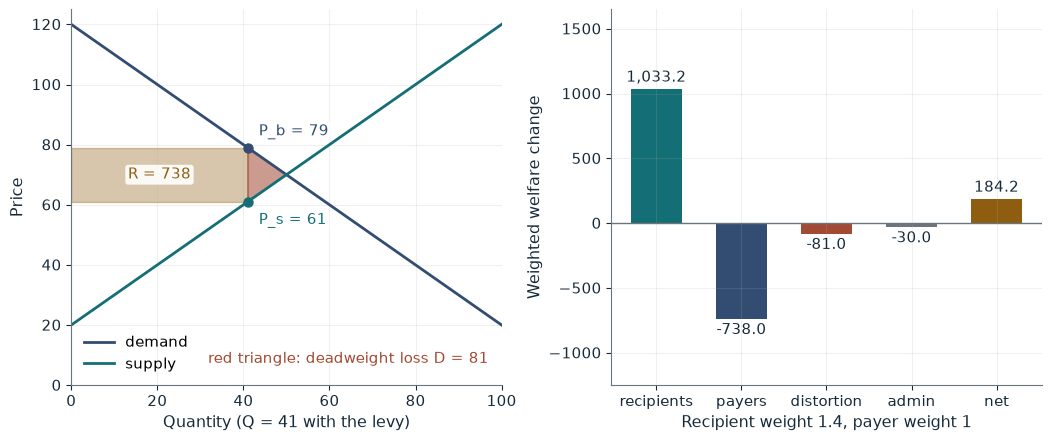

Seller price P_s        61
Buyer price P_b         79
Quantity Q              41
Revenue R               738
Deadweight loss D       81
Administration          30
Welfare change Delta W  184.2

Worked steps:
  1. 120 - (P_s + 18) = P_s - 20, so P_s = 61, P_b = 79, Q = 41
  2. R = 18 x 41 = 738
  3. D = 0.5 x 18 x 9 = 81
  4. Delta W = 1.4 x 738 - 738 - 81 - 30 = 1,033.2 - 849 = 184.2

A levy of 18 splits evenly: buyers pay 79 and sellers get 61, each 9 away from 70. It raises 738 at a distortion of 81, and administration uses 30. With recipient weight 1.4, Delta W = 1.4 x 738 - 738 - 81 - 30 = 184.2, so the transfer raises measured welfare. The 81 and 30 are resource losses under any weights; only the normative weight moves the ranking.


In [8]:
show(weights_picture(t=18, w=1.4))

Change one input, `w`, and hold the others at the book's values:

In [9]:
sweep(weights_picture, 'w', [1.0, 1.2, 1.4], {'t': 18}, ['Revenue R', 'Deadweight loss D', 'Welfare change Delta W'])

w | Revenue R | Deadweight loss D | Welfare change Delta W
1.0 | 738 | 81 | -111.0
1.2 | 738 | 81 | 36.6
1.4 | 738 | 81 | 184.2


With equal weights the transfer cancels and Delta W = -111; with recipient weight 1.4 it is 184.2. The 81 distortion and the 30 of administration are losses under either weight.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

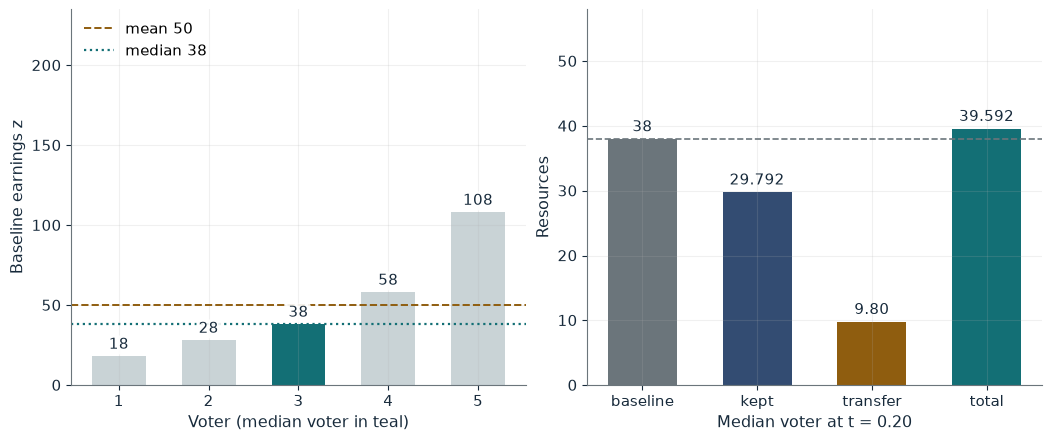

Mean earnings                    50
Response factor 1 - 0.1t         0.98
Mean taxable earnings            49.00
Transfer b                       9.80
Median taxable earnings y_m      37.24
Median disposable resources c_m  39.592
Change from baseline 38          1.592

Worked steps:
  1. Mean = (18 + 28 + 38 + 58 + 108) / 5 = 50
  2. Response factor = 1 - 0.1 x 0.20 = 0.98
  3. Mean taxable earnings = 0.98 x 50 = 49.00
  4. b = 0.20 x 49.00 = 9.80
  5. y_m = 0.98 x 38 = 37.24
  6. c_m = 0.80 x 37.24 + 9.80 = 29.792 + 9.80 = 39.592

The top earner's 108 pulls the mean to 50, while the median stays at 38. At t = 0.20 taxable earnings shrink by the factor 0.98, so the equal transfer is 0.20 x 49.00 = 9.80. The median voter keeps 0.80 x 37.24 = 29.792 and ends with c_m = 39.592, above the baseline 38. This is a mechanical comparison: it leaves the value of extra leisure uncounted and does not show that this rate is the voter's best one.


In [10]:
show(median_voter_picture(top=108, t=0.20))

## Practice

**1.** With top income 158 and t = 0.20, what are the median voter's disposable resources?

<details><summary>Answer</summary>

Mean 60, taxable mean 0.98 x 60 = 58.80, b = 0.20 x 58.80 = 11.76, c_m = 0.80 x 37.24 + 11.76 = 41.552.

</details>

**2.** At 50 percent coverage, does the household prepare?

<details><summary>Answer</summary>

J_N = 0.50 x 120 = 60 and J_P = 24 + 0.50 x 50 = 49; since 49 < 60 it prepares.

</details>

**3.** At weight 1.0 and levy 18, what is Delta W?

<details><summary>Answer</summary>

738 - 738 - 81 - 30 = -111.

</details>